# Tearsheet van een aandeel

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yf
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import grangercausalitytests

#Clear output
from google.colab import output
output.clear()

# Bedrijfs- en koersinformatie

In [4]:
msft_ticker = 'MSFT'
msft = yf.Ticker(msft_ticker)

# Haal de informatie op
msft_info = msft.info

# Extract de gevraagde details
company_name = msft_info.get('shortName', 'N/A')
sector = msft_info.get('sector', 'N/A')
industry = msft_info.get('industry', 'N/A')

# Extract de gevraagde extra details
current_price = msft_info.get('currentPrice', 'N/A')
market_cap = msft_info.get('marketCap', 'N/A')
fifty_two_week_high = msft_info.get('fiftyTwoWeekHigh', 'N/A')
fifty_two_week_low = msft_info.get('fiftyTwoWeekLow', 'N/A')
average_volume = msft_info.get('averageVolume', 'N/A') # Or 'averageDailyVolume10Day' if preferred

# De beschrijving kan lang zijn, neem de eerste zin of een samenvatting
long_business_summary = msft_info.get('longBusinessSummary', 'N/A')
sentence_end = long_business_summary.find('.')
activity_description = long_business_summary[:sentence_end + 1] if sentence_end != -1 else long_business_summary

# Peildatum: yfinance geeft geen specifieke peildatum voor de 'info' dict, dus gebruiken we de huidige datum van ophalen
data_as_of_date = dt.date.today().strftime('%Y-%m-%d')

# Toon de informatie
print(f"### Bedrijfsinformatie voor {msft_ticker}:\n")
print(f"**Bedrijfsnaam en ticker:** {company_name} ({msft_ticker})")
print(f"**Sector en industrie:** {sector} / {industry}")
print(f"**Beschrijving van de activiteit:** {activity_description}")
print(f"**Peildatum van de gegevens:** {data_as_of_date}\n")

print(f"### Koersinformatie:\n")
print(f"**Huidige koers:** ${current_price}")
print(f"**Marktkapitalisatie:** ${market_cap:,.2f}")
print(f"**52-weken bandbreedte:** ${fifty_two_week_low} - ${fifty_two_week_high}")
print(f"**Gemiddeld dagelijks handelsvolume:** {average_volume:,}")

### Bedrijfsinformatie voor MSFT:

**Bedrijfsnaam en ticker:** Microsoft Corporation (MSFT)
**Sector en industrie:** Technology / Software - Infrastructure
**Beschrijving van de activiteit:** Microsoft Corporation develops and supports software, services, devices, and solutions worldwide.
**Peildatum van de gegevens:** 2026-05-26

### Koersinformatie:

**Huidige koers:** $418.57
**Marktkapitalisatie:** $3,109,320,130,560.00
**52-weken bandbreedte:** $356.28 - $555.45
**Gemiddeld dagelijks handelsvolume:** 33,764,611


# Income statement

In [7]:
msft_financials = msft.financials
msft_annual_income_statement = msft.get_income_stmt(freq='yearly')

# Display the income statement for context
print("### Microsoft Annual Income Statement (Last 5 Years):\n")
display(msft_annual_income_statement.head())


### Microsoft Annual Income Statement (Last 5 Years):



,2025-06-30,2024-06-30,2023-06-30,2022-06-30
TaxEffectOfUnusualItems,-7.708800e+07,-9.991800e+07,-2.850000e+06,4.375400e+07
TaxRateForCalcs,1.760000e-01,1.820000e-01,1.900000e-01,1.310000e-01
NormalizedEBITDA,1.606030e+11,1.335580e+11,1.051550e+11,9.990500e+10
TotalUnusualItems,-4.380000e+08,-5.490000e+08,-1.500000e+07,3.340000e+08
TotalUnusualItemsExcludingGoodwill,-4.380000e+08,-5.490000e+08,-1.500000e+07,3.340000e+08


In [13]:
# Execute the cell to display the financial overview
# The content of this cell was previously defined as 1ba17cc6

financial_data = []
years = msft_annual_income_statement.columns[:5] # Get the last 5 available years

for year in years:
    revenue = msft_annual_income_statement.loc['TotalRevenue', year]
    cost_of_revenue = msft_annual_income_statement.loc['CostOfRevenue', year]
    gross_profit = revenue - cost_of_revenue # Calculate gross profit

    # Check for EBIT key, if not present, calculate
    if 'EBIT' in msft_annual_income_statement.index:
        ebit = msft_annual_income_statement.loc['EBIT', year]
    elif 'OperatingExpenses' in msft_annual_income_statement.index:
        operating_expenses = msft_annual_income_statement.loc['OperatingExpenses', year]
        ebit = gross_profit - operating_expenses
    else:
        ebit = 'N/A' # Fallback if EBIT and OperatingExpenses are missing

    # Check for Net Income key
    if 'Net Income' in msft_annual_income_statement.index:
        net_income = msft_annual_income_statement.loc['Net Income', year]
    elif 'NetIncome' in msft_annual_income_statement.index:
        net_income = msft_annual_income_statement.loc['NetIncome', year]
    else:
        net_income = 'N/A' # Fallback if Net Income is also missing

    # Calculate margins, handle cases where revenue or other metrics might be N/A or zero
    gross_margin = (gross_profit / revenue) * 100 if revenue and isinstance(gross_profit, (int, float)) else 'N/A'
    ebit_margin = (ebit / revenue) * 100 if revenue and isinstance(ebit, (int, float)) else 'N/A'
    net_margin = (net_income / revenue) * 100 if revenue and isinstance(net_income, (int, float)) else 'N/A'

    financial_data.append({
        'Year': year.year,
        'Revenue': revenue,
        'EBIT': ebit,
        'Net Income': net_income,
        'Gross Margin (%)': gross_margin,
        'EBIT Margin (%)': ebit_margin,
        'Net Margin (%)': net_margin
    })

df_financials = pd.DataFrame(financial_data)

print("### Financiële Overzicht (Laatste 5 Jaar):\n")
display(df_financials)


### Financiële Overzicht (Laatste 5 Jaar):



,Year,Revenue,EBIT,Net Income,Gross Margin (%),EBIT Margin (%),Net Margin (%)
0,2025,2.817240e+11,1.260120e+11,1.018320e+11,68.823742,44.728884,36.146015
1,2024,2.451220e+11,1.107220e+11,8.813600e+10,69.764444,45.170160,35.955973
2,2023,2.119150e+11,9.127900e+10,7.236100e+10,68.920086,43.073402,34.146238
3,2022,1.982700e+11,8.577900e+10,7.273800e+10,68.401674,43.263731,36.686337


# Waardering

In [8]:
# Waarderingsmultiples
pe_ratio = msft_info.get('trailingPE', 'N/A')
ev_ebitda = msft_info.get('enterpriseToEbitda', 'N/A')
price_to_sales = msft_info.get('priceToSalesTrailing12Months', 'N/A')
price_to_book = msft_info.get('priceToBook', 'N/A')

print("### Waarderingsmultiples (Actueel):\n")
print(f"**P/E Ratio:** {pe_ratio:.2f}" if isinstance(pe_ratio, (int, float)) else f"**P/E Ratio:** {pe_ratio}")
print(f"**EV/EBITDA:** {ev_ebitda:.2f}" if isinstance(ev_ebitda, (int, float)) else f"**EV/EBITDA:** {ev_ebitda}")
print(f"**P/S Ratio:** {price_to_sales:.2f}" if isinstance(price_to_sales, (int, float)) else f"**P/S Ratio:** {price_to_sales}")
print(f"**P/B Ratio:** {price_to_book:.2f}" if isinstance(price_to_book, (int, float)) else f"**P/B Ratio:** {price_to_book}")

### Waarderingsmultiples (Actueel):

**P/E Ratio:** 24.94
**EV/EBITDA:** 17.11
**P/S Ratio:** 9.77
**P/B Ratio:** 7.50


# Analisteninformatie

In [9]:
# Analisten Doelkoers
target_mean_price = msft_info.get('targetMeanPrice', 'N/A')
target_high_price = msft_info.get('targetHighPrice', 'N/A')
target_low_price = msft_info.get('targetLowPrice', 'N/A')

print("\n### Analisten Doelkoers:\n")
print(f"**Gemiddelde doelkoers:** ${target_mean_price:.2f}" if isinstance(target_mean_price, (int, float)) else f"**Gemiddelde doelkoers:** {target_mean_price}")
print(f"**Hoogste doelkoers:** ${target_high_price:.2f}" if isinstance(target_high_price, (int, float)) else f"**Hoogste doelkoers:** {target_high_price}")
print(f"**Laagste doelkoers:** ${target_low_price:.2f}" if isinstance(target_low_price, (int, float)) else f"**Laagste doelkoers:** {target_low_price}")


### Analisten Doelkoers:

**Gemiddelde doelkoers:** $560.63
**Hoogste doelkoers:** $870.00
**Laagste doelkoers:** $400.00


In [10]:
# Aanbevelingsverdeling (voor de meest recente aanbeveling)
recommendation_key = msft_info.get('recommendationKey', 'N/A') # e.g., 'buy', 'hold', 'sell'
number_of_analysts = msft_info.get('numberOfAnalystOpinions', 'N/A')

print("\n### Aanbeveling van Analisten:\n")
print(f"**Algemene aanbeveling:** {recommendation_key}")
print(f"**Aantal analisten:** {number_of_analysts}")

# For a more detailed breakdown (Buy/Hold/Sell counts), yfinance offers `msft.recommendations_summary()`,
# but it's not directly in `msft.info`. Let's just use the key for now.



### Aanbeveling van Analisten:

**Algemene aanbeveling:** strong_buy
**Aantal analisten:** 54


# Financiële Kengetallen

In [14]:
cash_position = msft_info.get('totalCash', 'N/A')
total_debt = msft_info.get('totalDebt', 'N/A')

if isinstance(cash_position, (int, float)) and isinstance(total_debt, (int, float)):
    net_debt = total_debt - cash_position
else:
    net_debt = 'N/A'

dividend_per_share = msft_info.get('dividendRate', 'N/A')
dividend_yield = msft_info.get('dividendYield', 'N/A')

roe = msft_info.get('returnOnEquity', 'N/A')
roa = msft_info.get('returnOnAssets', 'N/A')
debt_to_equity = msft_info.get('debtToEquity', 'N/A')

print(f"**Kaspositie:** ${cash_position:,.2f}" if isinstance(cash_position, (int, float)) else f"**Kaspositie:** {cash_position}")
print(f"**Nettoschuld:** ${net_debt:,.2f}" if isinstance(net_debt, (int, float)) else f"**Nettoschuld:** {net_debt}")
print(f"**Dividend per aandeel (Jaarlijks):** ${dividend_per_share:.2f}" if isinstance(dividend_per_share, (int, float)) else f"**Dividend per aandeel (Jaarlijks):** {dividend_per_share}")
print(f"**Dividendrendement:** {dividend_yield:.2%}" if isinstance(dividend_yield, (int, float)) else f"**Dividendrendement:** {dividend_yield}")
print(f"**Return on Equity (ROE):** {roe:.2%}" if isinstance(roe, (int, float)) else f"**Return on Equity (ROE):** {roe}")
print(f"**Return on Assets (ROA):** {roa:.2%}" if isinstance(roa, (int, float)) else f"**Return on Assets (ROA):** {roa}")
print(f"**Debt/Equity-ratio:** {debt_to_equity:.2f}" if isinstance(debt_to_equity, (int, float)) else f"**Debt/Equity-ratio:** {debt_to_equity}")

**Kaspositie:** $78,227,996,672.00
**Nettoschuld:** $47,203,999,744.00
**Dividend per aandeel (Jaarlijks):** $3.64
**Dividendrendement:** 87.00%
**Return on Equity (ROE):** 34.01%
**Return on Assets (ROA):** 14.81%
**Debt/Equity-ratio:** 30.27


# Grafieken


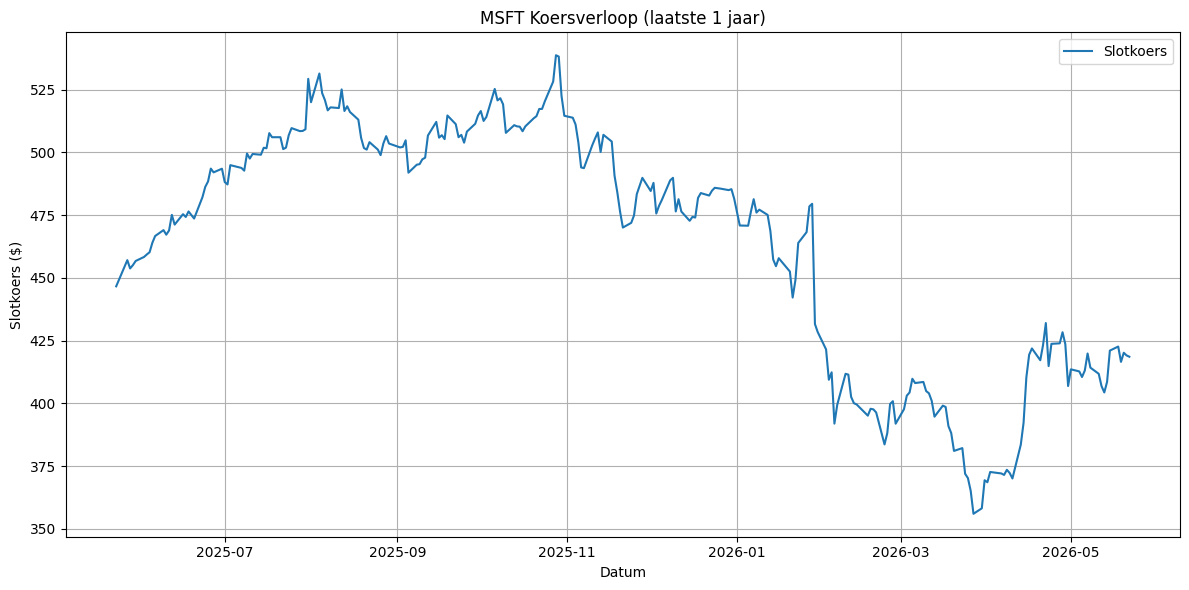

In [15]:
hist = msft.history(period="1y") # Get 1 year of historical data

plt.figure(figsize=(12, 6))
plt.plot(hist.index, hist['Close'], label='Slotkoers')
plt.title('MSFT Koersverloop (laatste 1 jaar)')
plt.xlabel('Datum')
plt.ylabel('Slotkoers ($)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

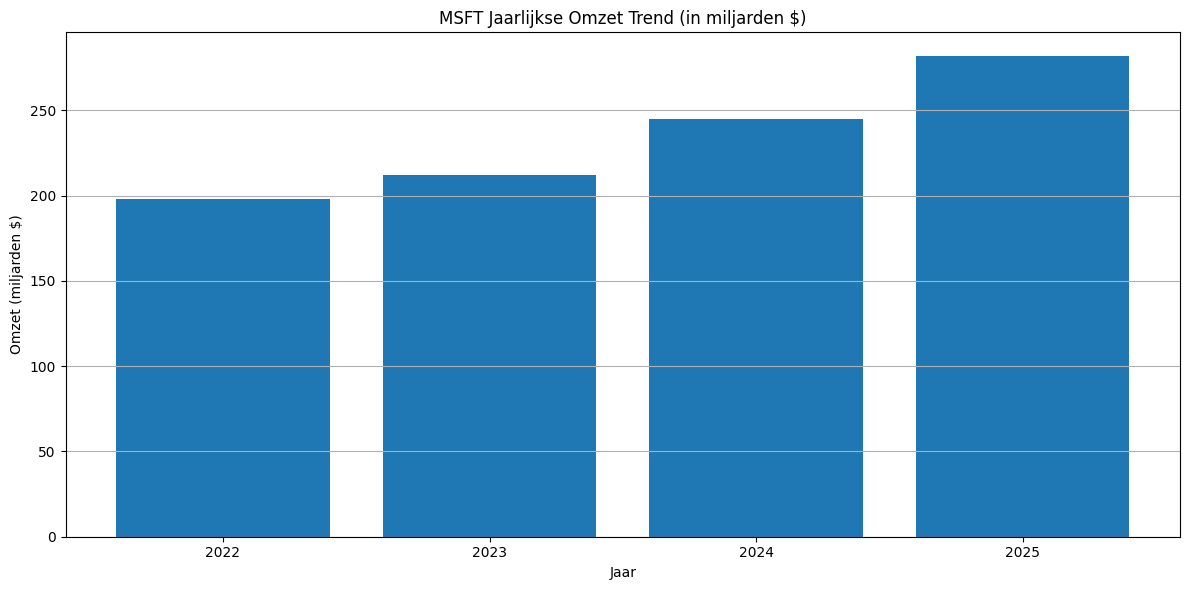

In [16]:
plt.figure(figsize=(12, 6))
plt.bar(df_financials['Year'], df_financials['Revenue'] / 1e9) # Divide by 1e9 for billions
plt.title('MSFT Jaarlijkse Omzet Trend (in miljarden $)')
plt.xlabel('Jaar')
plt.ylabel('Omzet (miljarden $)')
plt.xticks(df_financials['Year'])
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Katalysatoren en Risico's

*   **Katalysatoren:** Sterke groei in clouddiensten (Azure), innovaties in AI en Copilot-producten, en continue vraag naar bedrijfsservices.
*   **Risico's:** Intensieve concurrentie in alle segmenten, regelgevingsdruk (antitrust), en macro-economische tegenwind die de IT-uitgaven kan beïnvloeden.
*   **Andere factoren:** Externe factoren zoals geopolitieke spanningen of verstoringen in de toeleveringsketen kunnen ook invloed hebben.

# Contactgegevens Management (Investor Relations)


In [17]:
ir_website = msft_info.get('irWebsite', 'N/A')
company_address = f"{msft_info.get('address1', '')}, {msft_info.get('city', '')}, {msft_info.get('state', '')} {msft_info.get('zip', '')}, {msft_info.get('country', '')}"
company_phone = msft_info.get('phone', 'N/A')

print(f"**Investor Relations Website:** {ir_website}")
print(f"**Bedrijfsadres:** {company_address}")
print(f"**Telefoonnummer:** {company_phone}")

**Investor Relations Website:** http://www.microsoft.com/investor/default.aspx
**Bedrijfsadres:** One Microsoft Way, Redmond, WA 98052-6399, United States
**Telefoonnummer:** 425 882 8080


### HTML Rapport Genereren

In [19]:
import io
import base64
import matplotlib.pyplot as plt

def get_plot_as_base64(plot_func, *args, **kwargs):
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_func(ax, *args, **kwargs)
    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight')
    plt.close(fig)
    image_base64 = base64.b64encode(buf.getvalue()).decode('utf-8')
    return f'<img src="data:image/png;base64,{image_base64}" alt="Plot">'

def plot_stock_price(ax, hist_df):
    ax.plot(hist_df.index, hist_df['Close'], label='Slotkoers')
    ax.set_title('MSFT Koersverloop (laatste 1 jaar)')
    ax.set_xlabel('Datum')
    ax.set_ylabel('Slotkoers ($)')
    ax.grid(True)
    ax.legend()

def plot_revenue(ax, df_financials_df):
    ax.bar(df_financials_df['Year'], df_financials_df['Revenue'] / 1e9)
    ax.set_title('MSFT Jaarlijkse Omzet Trend (in miljarden $)')
    ax.set_xlabel('Jaar')
    ax.set_ylabel('Omzet (miljarden $)')
    ax.set_xticks(df_financials_df['Year'])
    ax.grid(axis='y')


# 1. Header: Bedrijfsinformatie
company_info_html = f"""
<h1>Tearsheet voor {company_name} ({msft_ticker})</h1>
<p><b>Sector en industrie:</b> {sector} / {industry}</p>
<p><b>Beschrijving van de activiteit:</b> {activity_description}</p>
<p><b>Peildatum van de gegevens:</b> {data_as_of_date}</p>
"""

# 2. First Row: Koersinformatie
stock_price_html = f"""
<h2>Koersinformatie</h2>
<p><b>Huidige koers:</b> ${current_price}</p>
<p><b>Marktkapitalisatie:</b> ${market_cap:,.2f}</p>
<p><b>52-weken bandbreedte:</b> ${fifty_two_week_low} - ${fifty_two_week_high}</p>
<p><b>Gemiddeld dagelijks handelsvolume:</b> {average_volume:,}</p>
"""

# 3. Second Row: Income Statement | Waardering | Financiële Kengetallen
income_statement_html = f"""
<h2>Financiële Overzicht (Laatste 5 Jaar)</h2>
{df_financials.to_html(index=False)}
"""

valuation_multiples_html = f"""
<h2>Waarderingsmultiples (Actueel)</h2>
<p><b>P/E Ratio:</b> {pe_ratio:.2f}</p>
<p><b>EV/EBITDA:</b> {ev_ebitda:.2f}</p>
<p><b>P/S Ratio:</b> {price_to_sales:.2f}</p>
<p><b>P/B Ratio:</b> {price_to_book:.2f}</p>
"""

financial_ratios_html = f"""
<h2>Overige Financiële Kengetallen</h2>
<p><b>Kaspositie:</b> ${cash_position:,.2f}</p>
<p><b>Nettoschuld:</b> ${net_debt:,.2f}</p>
<p><b>Dividend per aandeel (Jaarlijks):</b> ${dividend_per_share:.2f}</p>
<p><b>Dividendrendement:</b> {dividend_yield:.2%}</p>
<p><b>Return on Equity (ROE):</b> {roe:.2%}</p>
<p><b>Return on Assets (ROA):</b> {roa:.2%}</p>
<p><b>Debt/Equity-ratio:</b> {debt_to_equity:.2f}</p>
"""

# 4. Third Row: Analisteninformatie
analyst_info_html = f"""
<h2>Analisteninformatie</h2>
<h3>Analisten Doelkoers:</h3>
<p><b>Gemiddelde doelkoers:</b> ${target_mean_price:.2f}</p>
<p><b>Hoogste doelkoers:</b> ${target_high_price:.2f}</p>
<p><b>Laagste doelkoers:</b> ${target_low_price:.2f}</p>
<h3>Aanbeveling van Analisten:</h3>
<p><b>Algemene aanbeveling:</b> {recommendation_key}</p>
<p><b>Aantal analisten:</b> {number_of_analysts}</p>
"""

# 5. Fourth Row: Grafieken
stock_price_plot_html = get_plot_as_base64(plot_stock_price, hist)
revenue_plot_html = get_plot_as_base64(plot_revenue, df_financials)

# 6. Fifth Row: Katalysatoren en Risico's
catalysts_risks_html = """
<h2>Katalysatoren en Risico's</h2>
<ul>
    <li><b>Katalysatoren:</b> Sterke groei in clouddiensten (Azure), innovaties in AI en Copilot-producten, en continue vraag naar bedrijfsservices.</li>
    <li><b>Risico's:</b> Intensieve concurrentie in alle segmenten, regelgevingsdruk (antitrust), en macro-economische tegenwind die de IT-uitgaven kan beïnvloeden.</li>
    <li><b>Andere factoren:</b> Externe factoren zoals geopolitieke spanningen of verstoringen in de toeleveringsketen kunnen ook invloed hebben.</li>
</ul>
"""

# 7. Last Row: Contactgegevens
contact_details_html = f"""
<h2>Contactgegevens Management (Investor Relations)</h2>
<p><b>Investor Relations Website:</b> {ir_website}</p>
<p><b>Bedrijfsadres:</b> {company_address}</p>
<p><b>Telefoonnummer:</b> {company_phone}</p>
"""

# Assemble the full HTML
full_html_content = f"""
<!DOCTYPE html>
<html>
<head>
    <title>Tearsheet voor {company_name}</title>
    <style>
        body {{ font-family: sans-serif; margin: 20px; color: #333; background-color: #f8f8f8; }}
        h1, h2, h3 {{ color: #1a2a46; border-bottom: 1px solid #eee; padding-bottom: 5px; margin-top: 20px; }}
        table {{ width: 100%; border-collapse: collapse; margin-bottom: 20px; background-color: white; box-shadow: 0 0 10px rgba(0,0,0,0.05); }}
        th, td {{ border: 1px solid #ddd; padding: 8px; text-align: left; }}
        th {{ background-color: #e9ecef; font-weight: bold; }}
        .row-container {{ display: flex; flex-wrap: wrap; margin-bottom: 20px; justify-content: space-between; }}
        .col-full {{ flex: 0 0 100%; padding: 10px; box-sizing: border-box; background-color: white; border-radius: 5px; box-shadow: 0 0 10px rgba(0,0,0,0.05); margin-bottom: 10px; }}
        .col-third {{ flex: 0 0 32%; padding: 10px; box-sizing: border-box; background-color: white; border-radius: 5px; box-shadow: 0 0 10px rgba(0,0,0,0.05); margin-bottom: 10px; }}
        .col-half {{ flex: 0 0 49%; padding: 10px; box-sizing: border-box; background-color: white; border-radius: 5px; box-shadow: 0 0 10px rgba(0,0,0,0.05); margin-bottom: 10px; }}
        img {{ max-width: 100%; height: auto; display: block; margin: 0 auto; }}
        @media (max-width: 768px) {{
            .col-third, .col-half, .col-full {{ flex: 0 0 100%; }}
        }}
    </style>
</head>
<body>

    {company_info_html}

    <div class="row-container">
        <div class="col-full">
            {stock_price_html}
        </div>
    </div>

    <div class="row-container">
        <div class="col-third">
            {income_statement_html}
        </div>
        <div class="col-third">
            {valuation_multiples_html}
        </div>
        <div class="col-third">
            {financial_ratios_html}
        </div>
    </div>

    <div class="row-container">
        <div class="col-full">
            {analyst_info_html}
        </div>
    </div>

    <div class="row-container">
        <div class="col-half">
            {stock_price_plot_html}
        </div>
        <div class="col-half">
            {revenue_plot_html}
        </div>
    </div>

    <div class="row-container">
        <div class="col-full">
            {catalysts_risks_html}
        </div>
    </div>

    <div class="row-container">
        <div class="col-full">
            {contact_details_html}
        </div>
    </div>

</body>
</html>
"""

# Save the HTML to a file
file_name = f"tearsheet_{msft_ticker.lower()}.html"
with open(file_name, 'w', encoding='utf-8') as f:
    f.write(full_html_content)

print(f"Rapport opgeslagen als: {file_name}")

Rapport opgeslagen als: tearsheet_msft.html
